<a href="https://colab.research.google.com/github/ronjaladhikari213/AI-related-projects/blob/main/FashionCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

In [25]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [26]:
df=pd.read_csv("fashion-mnist_train.csv")
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


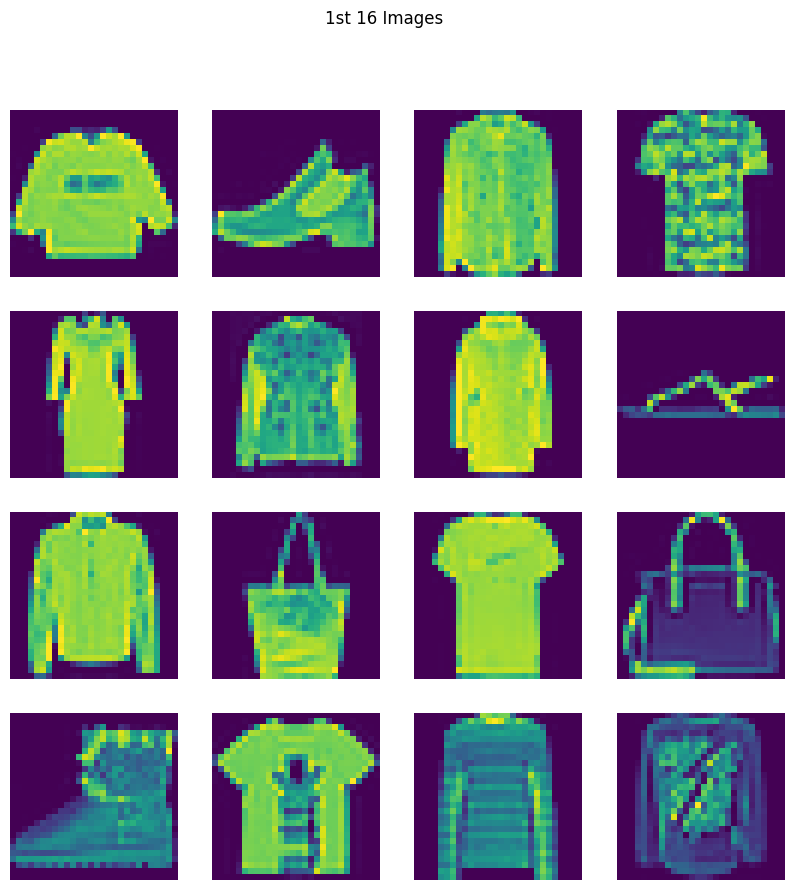

In [27]:
fig, axes = plt.subplots(4,4,figsize=(10,10))
fig.suptitle("1st 16 Images")
for i,ax in enumerate(axes.flat):
  img=df.iloc[i,1:].values.reshape(28,28)
  ax.imshow(img)
  ax.axis("off")


In [28]:
X = df.iloc[:,1:].values
y = df.iloc[:,0].values
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.2,random_state=42)
X_train = X_train/255.0
X_test = X_test/255.0

In [29]:
class CustomDataset(Dataset):
  def __init__(self,X,y):
    self.features = torch.tensor(X,dtype=torch.float32).reshape(-1,1,28,28)
    self.labels = torch.tensor(y,dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self,index):
    return self.features[index],self.labels[index]

In [30]:
train_dataset = CustomDataset(X_train,y_train)
test_dataset = CustomDataset(X_test,y_test)

In [31]:
train_dataloader = DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True)
test_dataloader = DataLoader(test_dataset,batch_size=32,shuffle=False,pin_memory=True)

In [38]:
class MyNN(nn.Module):
  def __init__(self,input_features):
    super().__init__()

    self.features = nn.Sequential(
        nn.Conv2d(input_features,32,kernel_size=3,stride=1,padding="same"),
        nn.ReLU(),
        nn.BatchNorm2d(32),
        nn.MaxPool2d(kernel_size=2,stride=2),

        nn.Conv2d(32,64,kernel_size=3,stride=1,padding="same"),
        nn.ReLU(),
        nn.BatchNorm2d(64),
        nn.MaxPool2d(kernel_size=2,stride=2)

    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64*7*7,128),
        nn.ReLU(),
        nn.Dropout(p=0.4),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Dropout(p=0.4),
        nn.Linear(64,10)
    )

  def forward(self,x):
      x = self.features(x)
      x = self.classifier(x)
      return x

In [39]:
lr=0.1
epochs=100

In [40]:
model = MyNN(1).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(),lr=lr, weight_decay=0.0001)

In [41]:
for epoch in range(epochs):
  for batch_features,batch_labels in train_dataloader:
    batch_features = batch_features.to(device)
    batch_labels = batch_labels.to(device)

    output = model(batch_features)
    loss = criterion(output,batch_labels)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()


In [42]:
#evaluation on train_data
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in train_dataloader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.991


In [43]:
# evaluation on test data
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_dataloader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.8946041666666666
